In [ ]:
pip install csiparser


Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
!pip install CSIKit

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 54 kB 2.7 MB/s 


In [ ]:
from CSIKit.filters.passband import lowpass
from CSIKit.filters.statistical import running_mean
from CSIKit.util.filters import hampel
from CSIKit.filters.wavelets.dwt import denoise

from CSIKit.reader import get_reader
from CSIKit.tools.batch_graph import BatchGraph
from CSIKit.util import csitools
from CSIKit.visualization.graph import Graph

import numpy as np

import math
import matplotlib.pyplot as plt
import numpy as np

from typing import Dict, Tuple

from CSIKit.visualization.metric import Metric
from matplotlib.colors import LinearSegmentedColormap

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import csiparser


In [ ]:
# Parse and filter CSI data
example_csi = (
    csiparser.ESP32("/content/drive/MyDrive/Dataset/ESP CSI Tool/No Movement/No2_cut.csv")
             .filter_by_sig_mode(1)
             .get_csi()
             .remove_null_subcarriers()
             .get_amplitude_from_csi()
             .get_phase_from_csi()
)



In [ ]:
my_reader = get_reader("/content/drive/MyDrive/Dataset/ESP CSI Tool/No Movement/No2_cut.csv")
csi_data = my_reader.read_file("/content/drive/MyDrive/Dataset/ESP CSI Tool/No Movement/No2_cut.csv", scaled=True)

In [ ]:
csi_matrix, no_frames, no_subcarriers = csitools.get_CSI(csi_data, metric='amplitude')
csi_matrix1, no_frames, no_subcarriers = csitools.get_CSI(csi_data, metric='phase')

In [ ]:
csi_matrix_first = csi_matrix[:, :, 0, 0]
csi_matrix_first1 = csi_matrix1[:, :, 0, 0]

In [ ]:
# Retrive amplitude and phase
amplitude_clean = example_csi.amplitude
phase_clean = example_csi.phase

In [ ]:
csi_matrix_squeezed = np.squeeze(csi_matrix_first)
csi_matrix_squeezed1 = np.squeeze(csi_matrix_first1)


In [ ]:
no_frames

149

In [ ]:
for x in range(no_frames):
  csi_matrix_squeezed[x] = hampel(csi_matrix_squeezed[x], 10, 3)
  csi_matrix_squeezed[x] = running_mean(csi_matrix_squeezed[x], 10)
  

/usr/local/lib/python3.7/dist-packages/numpy/core/_methods.py:202: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


In [ ]:
csi_matrix_squeezed[x]

array([-34.20279912, -34.20279912, -35.16068469, -35.70650124,
       -35.96903807, -36.09076022, -38.91112325, -37.15032099,
       -37.20027537, -37.26628397, -37.27605037, -37.34302763,
       -37.39071104, -37.45089825, -37.56398902, -37.66800421,
       -37.71566038, -37.79952754, -37.8833947 , -37.98904446,
       -38.08749361, -38.1713955 , -38.29455068, -38.37845257,
       -38.48847671, -38.63955787, -38.79063904, -38.88180517,
       -38.94215317, -39.04785734, -39.17446107, -39.2514905 ,
       -39.38142819, -39.45845763, -39.53667389, -39.61489016,
       -39.65912411, -39.79210992, -39.82350043, -39.860484  ,
       -39.92327483, -39.95085835, -39.93082444, -40.00140552,
       -40.02436916, -40.00790972, -40.02203436, -39.95628233,
       -39.96407257, -39.93243973, -39.90080688, -39.86495083,
       -39.86495083, -39.82195328, -39.77895573, -39.77895573,
       -39.77895573, -39.77895573, -39.73953263, -39.73953263,
       -39.73395998, -39.7762823 , -39.77947378, -39.78

In [ ]:
len(csi_matrix_squeezed)

149

In [ ]:
for x in range(no_frames):
  csi_matrix_squeezed1[x] = hampel(csi_matrix_squeezed1[x], 10, 3)
  csi_matrix_squeezed1[x] = running_mean(csi_matrix_squeezed1[x], 10)
  

In [ ]:
# Import Matplotlib to plot amplitude and phase from CSI data
%matplotlib inline
import matplotlib.pyplot as plt

# Import Numpy for scalling plot axis
import numpy as np

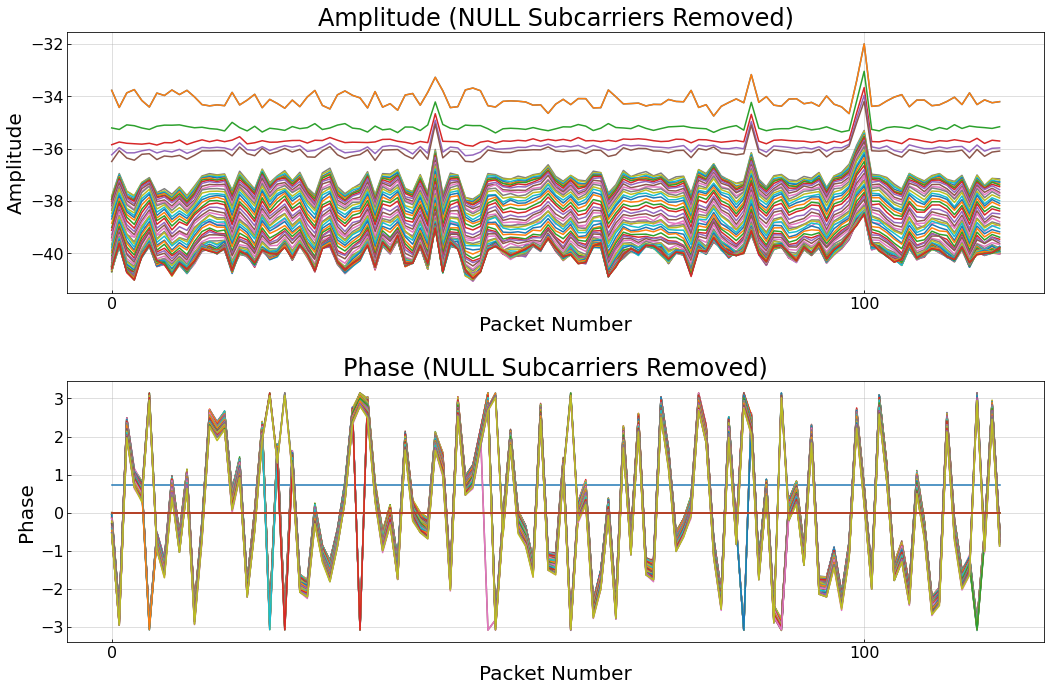

In [ ]:
# plt.style.use('default')

SMALL_SIZE = 16
MEDIUM_SIZE = 20
BIGGER_SIZE = 24
plt.rc('font', size=MEDIUM_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

amp_x = [i for i in range(csi_matrix_squeezed.shape[0])]
phase_x = [i for i in range(csi_matrix_squeezed1.shape[0])]



fig, ax = plt.subplots(2, 1)
ax[0].plot(amp_x, csi_matrix_squeezed)
# ax[0].plot(amp_x, 20*np.log10(np.abs(amplitude_clean)))

ax[0].set(xlabel='Packet Number', ylabel='Amplitude',
       title='Amplitude (NULL Subcarriers Removed)')
ax[0].grid()
ax[0].tick_params(direction='in', grid_alpha=0.5)
ax[0].set_xticks(np.arange(0, len(amp_x)+1, 100))


ax[1].plot(phase_x, csi_matrix_squeezed1)

ax[1].set(xlabel='Packet Number', ylabel='Phase',
       title='Phase (NULL Subcarriers Removed)')
ax[1].grid()
ax[1].tick_params(direction='in', grid_alpha=0.5)
ax[1].set_xticks(np.arange(0, len(phase_x)+1, 100))

fig.set_figheight(10)
fig.set_figwidth(15)
fig.savefig("After FIltering.png")

plt.tight_layout()
plt.show()

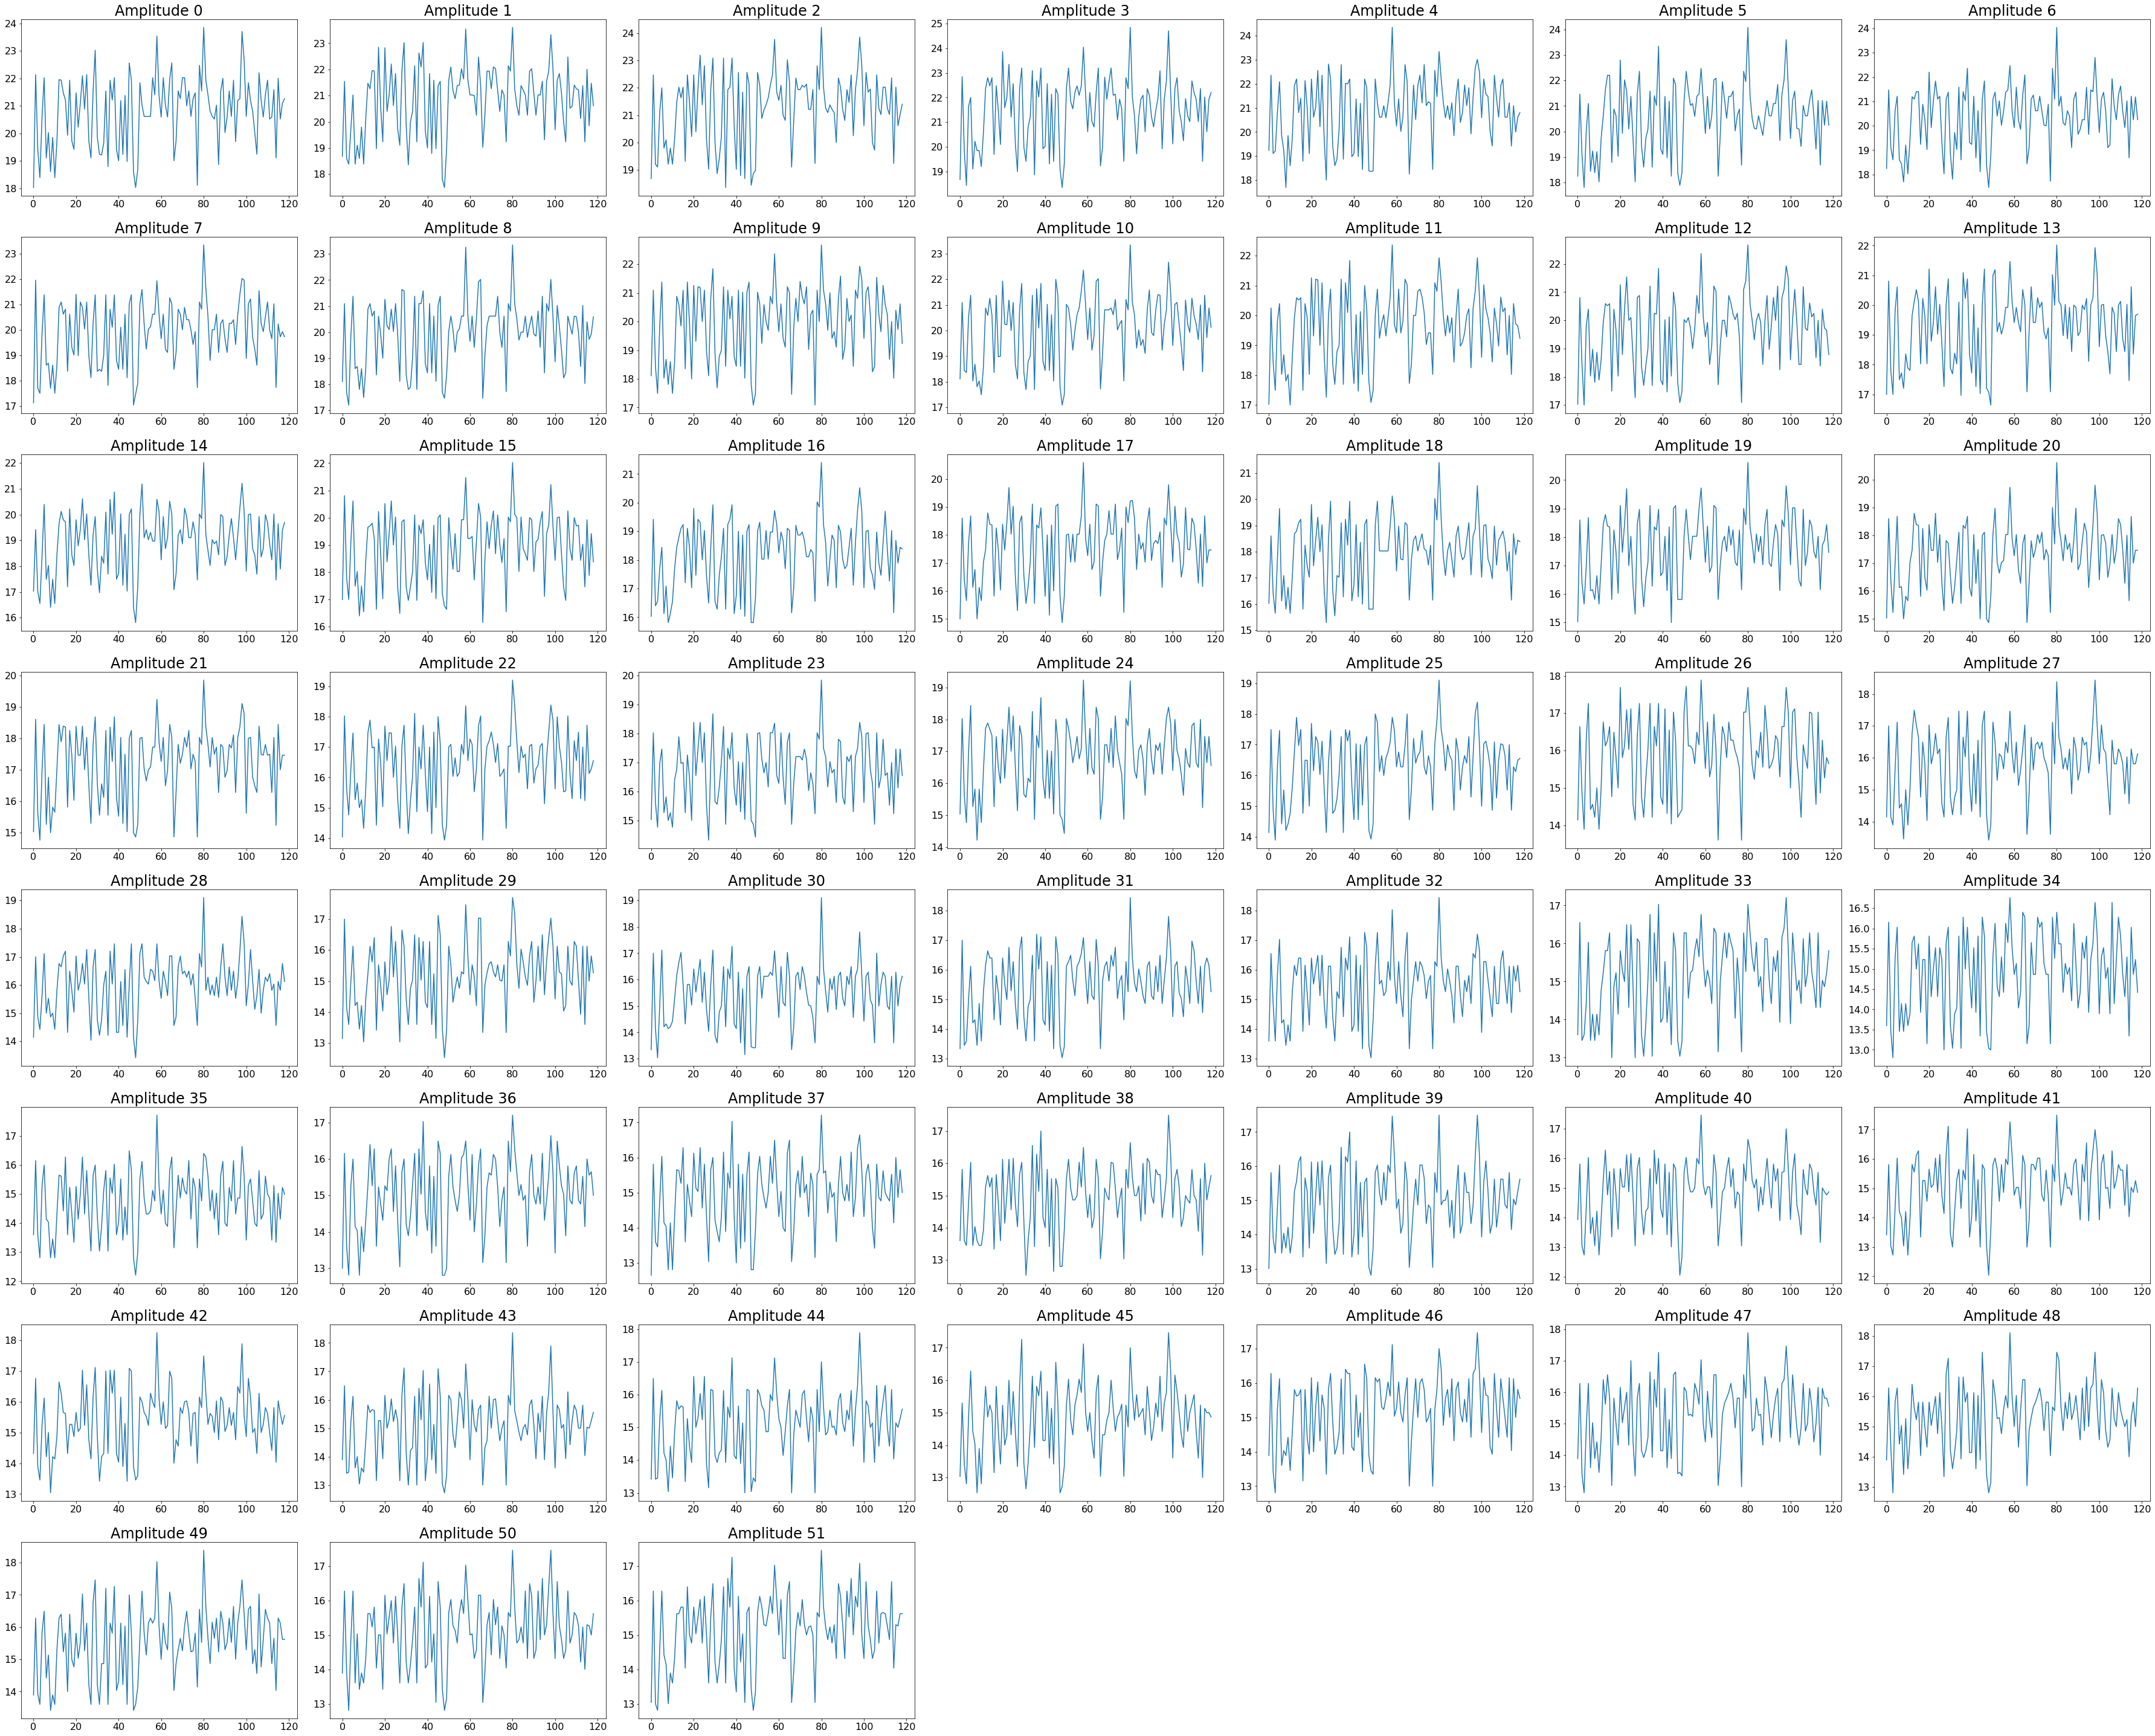

In [ ]:
# Retrive amplitude and phase
# amplitude = csi_matrix_squeezed
# phase = example_csi.phase
# Ref: https://stackoverflow.com/questions/12319796/dynamically-add-create-subplots-in-matplotlib

amplitude = amplitude_clean

Tot = amplitude.shape[1] #192 (Including Guard, NULL and Data Subcarriers)
Cols = int(Tot**0.5)

# Compute Rows required

Rows = Tot // Cols 
Rows += Tot % Cols

# Create a Position index

Position = range(1,Tot + 1)

# Create main figure

x = [i for i in range(amplitude.shape[1])]

fig = plt.figure(1)
fig.patch.set_facecolor('xkcd:white')
fig.set_figheight(50)
fig.set_figwidth(50)
for k in range(Tot):

  # add every single subplot to the figure with a for loop

  ax = fig.add_subplot(Rows,Cols,Position[k])
  ax.title.set_text('Amplitude {}'.format(k))
  ax.plot(amplitude.T[k])

plt.tight_layout() 
plt.show()